# Calibration trends

All stacks of one telescope made by `calib_stack.ipynb`, in time: one point per stack at the middle of its nights, the
horizontal bar = its nights. Bias: the level (median of the `mean` map) with the noise (median of the `std` map, the read
noise of a pixel) as the vertical bar. Dark: the level (median of the `mean` map) in ADU/s with the dark noise (median of `std_excess`, the noise of the
dark signal without the read noise) as the vertical bar, one colour per exposure time.

The vertical bar is the noise of **one pixel in one frame**, not the uncertainty of the level: the level of a stack is
the median over 4 million pixels and its own uncertainty is far below the bar.

In [1]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

TEL = 'wk06'

BIAS_DIR = os.path.expanduser(f'~/data/ocm_bias/{TEL}')
DARK_DIR = os.path.expanduser(f'~/data/ocm_dark/{TEL}')

## Bias

1300-1310   level  300.153   noise  6.983 ADU   209 zeros
1310-1320   level  300.117   noise  6.903 ADU   162 zeros
1320-1330   level  300.235   noise  6.723 ADU   85 zeros
1330-1340   level  300.119   noise  7.061 ADU   151 zeros


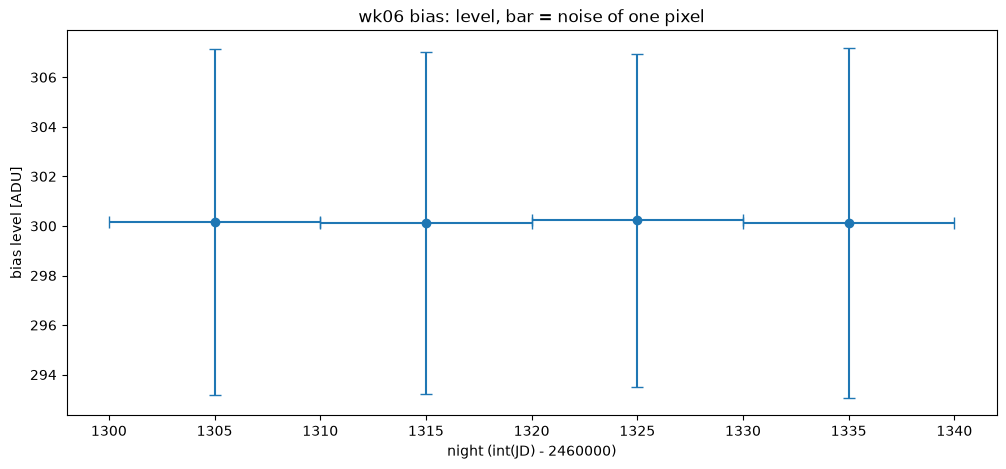

In [2]:
bias = []  # (first night, last night, level, noise, number of zeros), one per stack
for f in sorted(glob.glob(f'{BIAS_DIR}/{TEL}_*_mean.fits')):
    h = fits.getheader(f)
    level = np.median(fits.getdata(f))
    noise = np.median(fits.getdata(f.replace('_mean.fits', '_std.fits')))
    bias.append((h['NIGHT-BG'], h['NIGHT-EN'], level, noise, h['NZERO']))
    print(f'{h["NIGHT-BG"]}-{h["NIGHT-EN"]}   level {level:8.3f}   noise {noise:6.3f} ADU   {h["NZERO"]} zeros')

bias = np.array(bias)
night = (bias[:, 0] + bias[:, 1]) / 2
half = (bias[:, 1] - bias[:, 0]) / 2

fig, ax = plt.subplots(figsize=(12, 5))
ax.errorbar(night, bias[:, 2], yerr=bias[:, 3], xerr=half, fmt='o', capsize=4)
ax.set_xlabel('night (int(JD) - 2460000)')
ax.set_ylabel('bias level [ADU]')
ax.set_title(f'{TEL} bias: level, bar = noise of one pixel')
plt.show()

## Dark

1330-1340   900 s   level  0.004988   noise  0.001356 ADU/s   12 darks


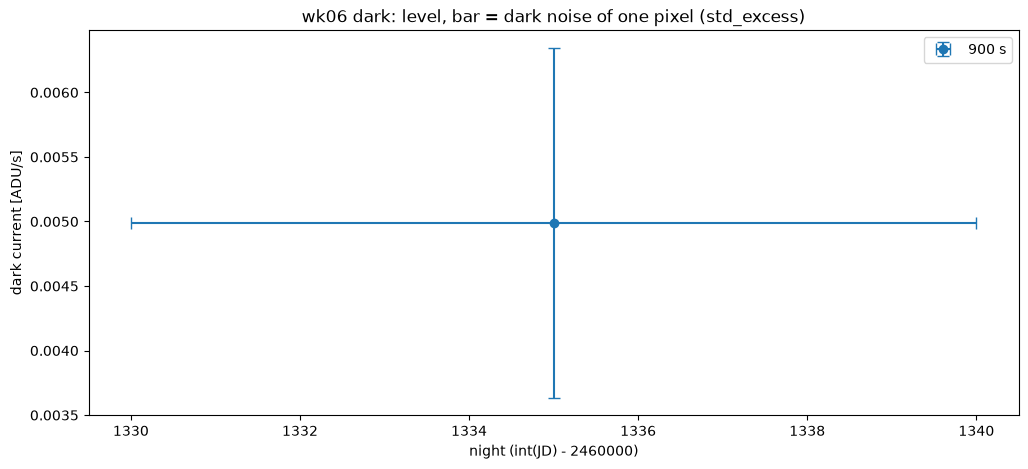

In [3]:
dark = []  # (first night, last night, exposure time, level, noise, number of darks), one per stack
for f in sorted(glob.glob(f'{DARK_DIR}/{TEL}_*_mean.fits')):
    h = fits.getheader(f)
    level = np.median(fits.getdata(f))
    noise = np.median(fits.getdata(f.replace('_mean.fits', '_std_excess.fits')))
    dark.append((h['NIGHT-BG'], h['NIGHT-EN'], round(h['EXPTIME']), level, noise, h['NDARK']))
    print(f'{h["NIGHT-BG"]}-{h["NIGHT-EN"]}   {round(h["EXPTIME"])} s   level {level:9.6f}   noise {noise:9.6f} ADU/s   {h["NDARK"]} darks')

dark = np.array(dark)
fig, ax = plt.subplots(figsize=(12, 5))
for t in sorted(set(dark[:, 2])):
    d = dark[dark[:, 2] == t]
    ax.errorbar((d[:, 0] + d[:, 1]) / 2, d[:, 3], yerr=d[:, 4], xerr=(d[:, 1] - d[:, 0]) / 2, fmt='o', capsize=4, label=f'{t:.0f} s')
ax.set_xlabel('night (int(JD) - 2460000)')
ax.set_ylabel('dark current [ADU/s]')
ax.set_title(f'{TEL} dark: level, bar = dark noise of one pixel (std_excess)')
ax.legend()
plt.show()